# Import Library

In [ ]:
# Library yang sering digunakan
import os, shutil
import zipfile
import random
from random import sample
import shutil
from shutil import copyfile
import pathlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm as tq

In [ ]:
# Libraries untuk pemrosesan data gambar
import cv2
from PIL import Image
import skimage
from skimage import io
from skimage.transform import resize
from skimage.transform import rotate, AffineTransform, warp
from skimage import img_as_ubyte
from skimage.exposure import adjust_gamma
from skimage.util import random_noise

In [ ]:
# Libraries untuk pembangunan model
import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
from tensorflow.keras import Model, layers
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.layers import GlobalAveragePooling2D, InputLayer, Conv2D, SeparableConv2D, MaxPooling2D, MaxPool2D, Dense, Flatten, Dropout, BatchNormalization, Input
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.applications import MobileNet, EfficientNetB4, EfficientNetB0
from tensorflow.keras.applications.densenet import DenseNet121
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint, Callback, EarlyStopping, ReduceLROnPlateau

In [ ]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [ ]:
print(tf.__version__)

2.19.0


# Load Dataset

In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"nabilasyalwani","key":"8c19bdab005ef2c18f7a9ba31d1a59d5"}'}

In [ ]:
!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download sovitrath/diabetic-retinopathy-224x224-2019-data

Dataset URL: https://www.kaggle.com/datasets/sovitrath/diabetic-retinopathy-224x224-2019-data
License(s): CC0-1.0
 90% 215M/238M [00:00<00:00, 543MB/s] 
100% 238M/238M [00:00<00:00, 551MB/s]


In [ ]:
!unzip /content/diabetic-retinopathy-224x224-2019-data.zip

Archive:  /content/diabetic-retinopathy-224x224-2019-data.zip
  inflating: colored_images/Mild/0024cdab0c1e.png  
  inflating: colored_images/Mild/00cb6555d108.png  
  inflating: colored_images/Mild/0124dffecf29.png  
  inflating: colored_images/Mild/01b3aed3ed4c.png  
  inflating: colored_images/Mild/0369f3efe69b.png  
  inflating: colored_images/Mild/03e25101e8e8.png  
  inflating: colored_images/Mild/04ac765f91a1.png  
  inflating: colored_images/Mild/059bc89df7f4.png  
  inflating: colored_images/Mild/05a5183c92d0.png  
  inflating: colored_images/Mild/0684311afdfc.png  
  inflating: colored_images/Mild/06b71823f9cd.png  
  inflating: colored_images/Mild/07929d32b5b3.png  
  inflating: colored_images/Mild/07a1c7073982.png  
  inflating: colored_images/Mild/086d41d17da8.png  
  inflating: colored_images/Mild/09935d72892b.png  
  inflating: colored_images/Mild/0a3202889f4d.png  
  inflating: colored_images/Mild/0a61bddab956.png  
  inflating: colored_images/Mild/0ad7f631dedb.png  
  

In [ ]:
# Direktori awal untuk train dan test
dataset_dir = "colored_images"

# Direktori baru untuk dataset gabungan
combined_dir = "dataset"

In [ ]:
os.makedirs(combined_dir, exist_ok=True)

# Pre-Processing

In [ ]:
# Preprocessing Function
def preprocess(img, show_steps=False):
    img_np = np.array(img)

    # 1) Image cropping
    gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
    ret, thresh = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    img_crop = cv2.boundingRect(contours[0])

    if len(contours) > 0:
        largest_contour = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(largest_contour)
        img_cropped = img.crop((x, y, x + w, y + h))
    else:
        img_cropped = img
    img_cropped = img_cropped.convert('RGB')

    # 2) Image denoising
    img_cropped_np = np.array(img_cropped)
    img_denoised_np = cv2.GaussianBlur(img_cropped_np, (3, 3), 0)

    # 3) Histogram equalization (HE)
    lab = cv2.cvtColor(img_denoised_np, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=5.0, tileGridSize=(8,8))
    cl = clahe.apply(l)
    limg = cv2.merge((cl,a,b))
    clahe_img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)

    # 4) Image resizing
    resize_img = Image.fromarray(clahe_img)
    resize_img = resize_img.resize((224, 224))

    if show_steps:
        fig, axes = plt.subplots(1, 5, figsize=(20, 5))
        axes[0].imshow(img)
        axes[0].set_title('Original')
        axes[0].axis('off')

        axes[1].imshow(img_cropped)
        axes[1].set_title('Cropped')
        axes[1].axis('off')

        axes[2].imshow(img_denoised_np)
        axes[2].set_title('Denoised')
        axes[2].axis('off')

        axes[3].imshow(clahe_img)
        axes[3].set_title('CLAHE)')
        axes[3].axis('off')

        axes[4].imshow(resize_img)
        axes[4].set_title('Resized')
        axes[4].axis('off')

        plt.tight_layout()
        plt.show()

    # return resize_img
    return resize_img

In [ ]:
# Direktori asal dan tujuan
source_dir = "colored_images"
target_dir = "dataset"

# Mapping folder asal ke folder target baru
pdr_category = 'Proliferate_DR'
npdr_categories = ['Mild', 'Moderate', 'Severe']
normal_category = 'No_DR'

# Pastikan direktori target ada
os.makedirs(os.path.join(target_dir, 'PDR'), exist_ok=True)
os.makedirs(os.path.join(target_dir, 'NPDR'), exist_ok=True)
os.makedirs(os.path.join(target_dir, 'Normal'), exist_ok=True)

# Salin gambar dari kategori 'no dr' ke 'normal'
normal_path = os.path.join(source_dir, normal_category)
for file in os.listdir(normal_path):
    src = os.path.join(normal_path, file)
    dst = os.path.join(target_dir, 'Normal', file)
    img = Image.open(src).convert("RGB")
    img = preprocess(img)
    img.save(dst)

# Salin gambar dari kategori NPDR ke 'npdr'
for npdr_cat in npdr_categories:
    dr_path = os.path.join(source_dir, npdr_cat)
    for file in os.listdir(dr_path):
        src = os.path.join(dr_path, file)
        dst = os.path.join(target_dir, 'NPDR', f"{npdr_cat}_{file}")
        img = Image.open(src).convert("RGB")
        img = preprocess(img)
        img.save(dst)

# Salin gambar dari kategori pdr ke 'pdr'
pdr_path = os.path.join(source_dir, pdr_category)
for file in os.listdir(pdr_path):
    src = os.path.join(pdr_path, file)
    dst = os.path.join(target_dir, 'PDR', file)
    img = Image.open(src).convert("RGB")
    img = preprocess(img)
    img.save(dst)

NameError: name 'os' is not defined

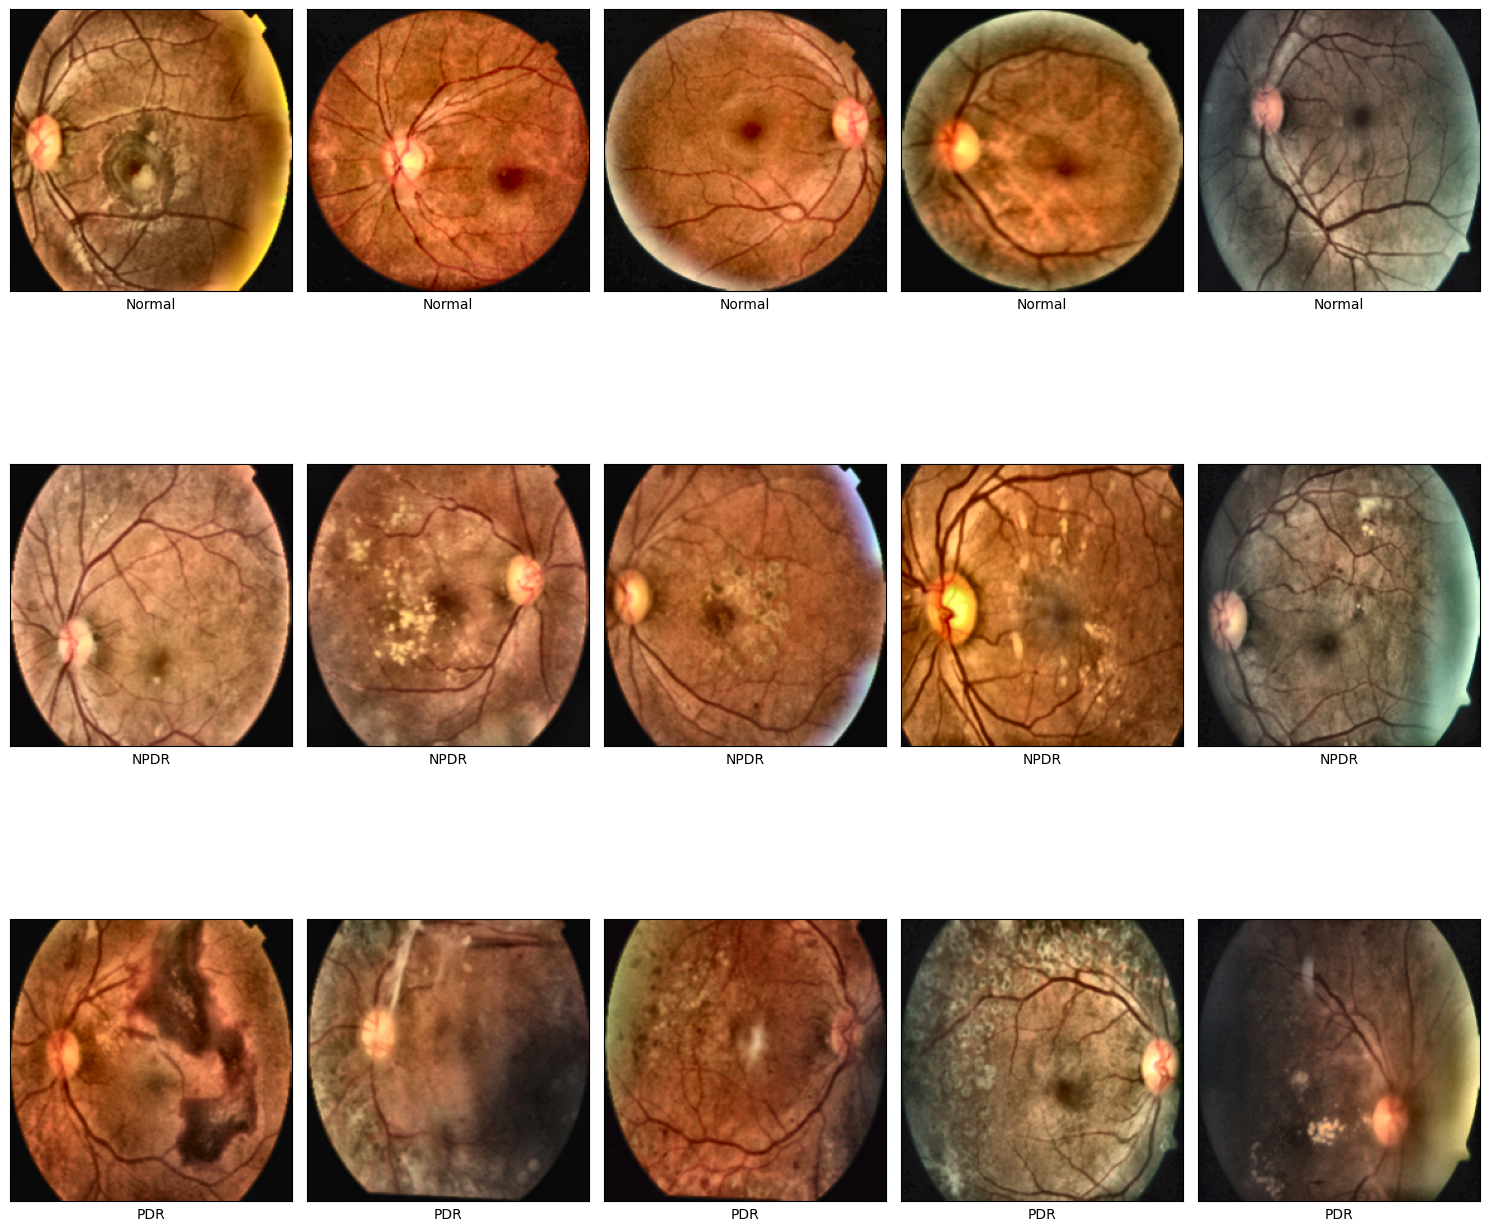

In [ ]:
fundus_image = {}

path = ""
path_sub = os.path.join(path, "dataset")
for i in os.listdir(path_sub):
  fundus_image[i] = os.listdir(os.path.join(path_sub, i))

path_sub = "dataset/"

fig, axs = plt.subplots(len(fundus_image.keys()), 5, figsize=(15, 15))

for i, class_name in enumerate(os.listdir(path_sub)):
    images = np.random.choice(fundus_image[class_name], 5, replace=False)

    for j, image_name in enumerate(images):
        img_path = os.path.join(path_sub, class_name, image_name)
        img = Image.open(img_path)
        img.save(img_path)
        axs[i, j].imshow(img)
        axs[i, j].set(xlabel=class_name, xticks=[], yticks=[])


fig.tight_layout()

In [ ]:
check_picture = "/content/dataset/NPDR/Mild_0024cdab0c1e.png"
img = Image.open(check_picture)
print(img.mode)

RGB


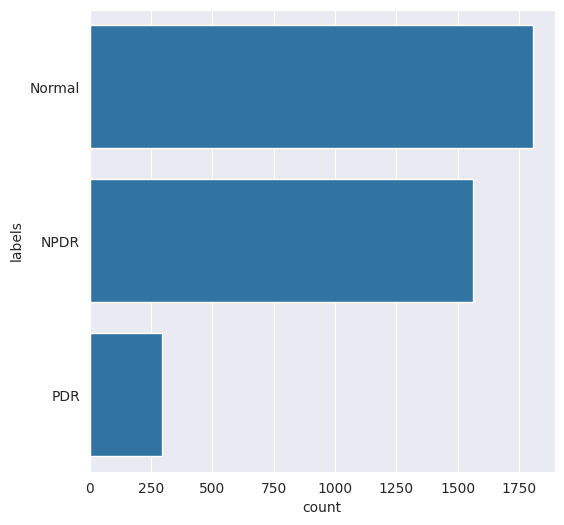

In [ ]:
fundus_path = "dataset/"

file_name = []
labels = []
full_path = []

for path, subdirs, files in os.walk(fundus_path):
  for name in files:
    full_path.append(os.path.join(path, name))
    labels.append(path.split('/')[-1])
    file_name.append(name)

distribution_train = pd.DataFrame({"path":full_path, 'file_name':file_name, "labels":labels})

Label = distribution_train['labels']
plt.figure(figsize = (6,6))
sns.set_style("darkgrid")
plot_data = sns.countplot(Label)

In [ ]:
mypath= 'dataset/'

file_name = []
labels = []
full_path = []
for path, subdirs, files in os.walk(mypath):
    for name in files:
        full_path.append(os.path.join(path, name))
        labels.append(path.split('/')[-1])
        file_name.append(name)

df = pd.DataFrame({"path":full_path,'file_name':file_name,"labels":labels})
# Melihat jumlah data gambar pada masing-masing label
df.groupby(['labels']).size()

,0
labels,
NPDR,1562
Normal,1805
PDR,295


In [ ]:
# Resize helper
def resize_img(img, size=(224,224)):
    return cv2.resize(img, size)

# CLAHE preprocessing
def apply_clahe(img):
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    cl = clahe.apply(l)
    limg = cv2.merge((cl,a,b))
    return cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)

# Rotasi berlawanan arah jarum jam
def anticlockwise_rotation(img):
    img = resize_img(img)
    sudut = random.randint(0,180)
    return rotate(img, sudut, preserve_range=True).astype(np.uint8)

# Rotasi searah jarum jam
def clockwise_rotation(img):
    img = resize_img(img)
    sudut = random.randint(0,180)
    return rotate(img, -sudut, preserve_range=True).astype(np.uint8)

# Flip vertical
def flip_up_down(img):
    img = resize_img(img)
    return np.flipud(img)

# Brightness
def add_brightness(img):
    img = resize_img(img)
    return adjust_gamma(img, gamma=0.5, gain=1)

# Blur
def blur_image(img):
    img = resize_img(img)
    return cv2.GaussianBlur(img, (9,9), 0)

# Shear
def sheared(img):
    img = resize_img(img)
    transform = AffineTransform(shear=0.2)
    shear_image = warp(img, transform, mode="wrap", preserve_range=True)
    return shear_image.astype(np.uint8)

# Warp shift (geser translasi)
def warp_shift(img):
    img = resize_img(img)
    transform = AffineTransform(translation=(0,40))
    warp_image = warp(img, transform, mode="wrap", preserve_range=True)
    return warp_image.astype(np.uint8)

# Augmentations
def rotate_image(img):
    angle = random.choice([0, 90, 180, 270])
    return rotate(img, angle, preserve_range=True).astype(np.uint8)

def flip_horizontal(img):
    return cv2.flip(img, 1)

def flip_vertical(img):
    return cv2.flip(img, 0)

def adjust_brightness(img):
    factor = random.uniform(0.8, 1.2)
    return np.clip(img * factor, 0, 255).astype(np.uint8)

def adjust_contrast(img):
    factor = random.uniform(0.8, 1.2)
    mean = np.mean(img, axis=(0,1), keepdims=True)
    img = (img - mean) * factor + mean
    return np.clip(img, 0, 255).astype(np.uint8)

def adjust_color(img):
    factor = random.uniform(0.8, 1.2)
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(np.float32)
    hsv[..., 1] *= factor
    hsv[..., 1] = np.clip(hsv[..., 1], 0, 255)
    img_colored = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)
    return img_colored

In [ ]:
# Membuat variabel transformasi yang akan menyimpan semua proses pra-pemrosesan yang telah dilakukan sebelumnya
transformations = { 'rotate image': rotate_image,
                    'flip horizontal': flip_horizontal,
                    'flip vertical': flip_vertical,
                    'adjust brightness': adjust_brightness,
                    'adjust contrast': adjust_contrast,
                    'adjust color': adjust_color,
                  }

subfolders = ["PDR", "NPDR"]
images_to_generate = [1210, 43]   # jumlah augmentasi per kelas

base_path = "dataset"

for subfolder, gen_count in zip(subfolders, images_to_generate):
    images_path = os.path.join(base_path, subfolder)
    images = [os.path.join(images_path, im) for im in os.listdir(images_path)]

    i = 1
    while i <= gen_count:
        image = random.choice(images)
        try:
            original_image = io.imread(image)

            if original_image.ndim == 2:  # grayscale
                original_image = cv2.cvtColor(original_image, cv2.COLOR_GRAY2RGB)

            original_image = resize_img(original_image)

            transformed_image = original_image.copy()
            transformation_count = random.randint(1,2)

            for _ in range(transformation_count):
                key = random.choice(list(transformations))
                transformed_image = transformations[key](transformed_image)

            new_image_path = f"{images_path}/augmented_{subfolder}_{i}.jpg"
            transformed_image = img_as_ubyte(transformed_image)
            cv2.imwrite(new_image_path, cv2.cvtColor(transformed_image, cv2.COLOR_RGB2BGR))
            i += 1

        except ValueError as e:
            print('Could not read', image, ':', e, 'skipping.')

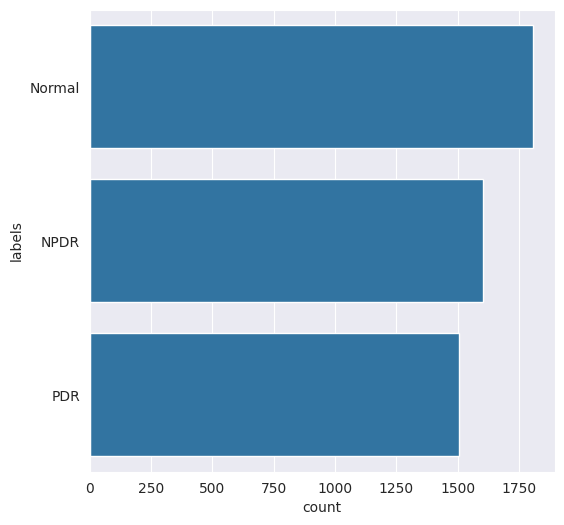

In [ ]:
fundus_path = "dataset/"

file_name = []
labels = []
full_path = []

for path, subdirs, files in os.walk(fundus_path):
  for name in files:
    full_path.append(os.path.join(path, name))
    labels.append(path.split('/')[-1])
    file_name.append(name)

distribution_train = pd.DataFrame({"path":full_path, 'file_name':file_name, "labels":labels})

Label = distribution_train['labels']
plt.figure(figsize = (6,6))
sns.set_style("darkgrid")
plot_data = sns.countplot(Label)

In [ ]:
mypath= 'dataset/'

file_name = []
labels = []
full_path = []
for path, subdirs, files in os.walk(mypath):
    for name in files:
        full_path.append(os.path.join(path, name))
        labels.append(path.split('/')[-1])
        file_name.append(name)

df = pd.DataFrame({"path":full_path,'file_name':file_name,"labels":labels})
# Melihat jumlah data gambar pada masing-masing label
df.groupby(['labels']).size()

,0
labels,
NPDR,1605
Normal,1805
PDR,1505


In [ ]:
df

,path,file_name,labels
0,dataset/Normal/5bf6f2958e53.png,5bf6f2958e53.png,Normal
1,dataset/Normal/2ef955d6d9ff.png,2ef955d6d9ff.png,Normal
2,dataset/Normal/57db4781e7ec.png,57db4781e7ec.png,Normal
3,dataset/Normal/4e8585a96739.png,4e8585a96739.png,Normal
4,dataset/Normal/5f6db235c04d.png,5f6db235c04d.png,Normal
...,...,...,...
4910,dataset/PDR/augmented_PDR_131.jpg,augmented_PDR_131.jpg,PDR
4911,dataset/PDR/augmented_PDR_875.jpg,augmented_PDR_875.jpg,PDR
4912,dataset/PDR/augmented_PDR_1112.jpg,augmented_PDR_1112.jpg,PDR
4913,dataset/PDR/augmented_PDR_1131.jpg,augmented_PDR_1131.jpg,PDR


In [ ]:
X= df['path']
y= df['labels']

# Split dataset awal menjadi data train dan test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=300)

In [ ]:
# Menyatukan ke dalam masing-masing dataframe
df_tr = pd.DataFrame({'path':X_train,'labels':y_train,'set':'train'})
df_te = pd.DataFrame({'path':X_test,'labels':y_test,'set':'test'})

In [ ]:
# Gabungkan DataFrame df_tr dan df_te
df_all = pd.concat([df_tr, df_te], ignore_index=True)

print('===================================================== \n')
print(df_all.groupby(['set', 'labels']).size(), '\n')
print('===================================================== \n')
print(df_all.sample(5))

datasource_path = "dataset/"
dataset_path = "Dataset-Final/"


set    labels
test   NPDR       326
       Normal     352
       PDR        305
train  NPDR      1279
       Normal    1453
       PDR       1200
dtype: int64 


                                        path  labels    set
1247         dataset/Normal/46acc506fa61.png  Normal  train
2249  dataset/NPDR/Moderate_6f4e0538d1e4.png    NPDR  train
3084         dataset/Normal/aa8a1e814811.png  Normal  train
3710  dataset/NPDR/Moderate_cb602182cde3.png    NPDR  train
2256       dataset/PDR/augmented_PDR_118.jpg     PDR  train


In [ ]:
for index, row in tq(df_all.iterrows()):
    file_path = row['path']
    if os.path.exists(file_path) == False:
            file_path = os.path.join(datasource_path,row['labels'],row['image'].split('.')[0])

    if os.path.exists(os.path.join(dataset_path,row['set'],row['labels'])) == False:
        os.makedirs(os.path.join(dataset_path,row['set'],row['labels']))

    destination_file_name = file_path.split('/')[-1]
    file_dest = os.path.join(dataset_path,row['set'],row['labels'],destination_file_name)

    if os.path.exists(file_dest) == False:
        shutil.copy2(file_path,file_dest)

0it [00:00, ?it/s]

In [ ]:
# Definisikan direktori training dan test
TRAIN_DIR = "Dataset-Final/train/"
TEST_DIR = "Dataset-Final/test/"

train_PDR = os.path.join(TRAIN_DIR + '/PDR')
train_NPDR = os.path.join(TRAIN_DIR + '/NPDR')
train_Normal = os.path.join(TRAIN_DIR + '/Normal')
test_PDR = os.path.join(TEST_DIR + '/PDR')
test_NPDR = os.path.join(TEST_DIR + '/NPDR')
test_Normal = os.path.join(TEST_DIR + '/Normal')

print("Total number of PDR images in training set: ",len(os.listdir(train_PDR)))
print("Total number of NPDR images in training set: ",len(os.listdir(train_NPDR)))
print("Total number of Normal images in training set: ",len(os.listdir(train_Normal)))

print("Total number of PDR images in test set: ",len(os.listdir(test_PDR)))
print("Total number of NPDR images in test set: ",len(os.listdir(test_NPDR)))
print("Total number of Normal images in test set: ",len(os.listdir(test_Normal)))

# train_Mild = os.path.join(TRAIN_DIR + '/Mild')
# train_Moderate = os.path.join(TRAIN_DIR + '/Moderate')
# train_No_DR = os.path.join(TRAIN_DIR + '/No_DR')
# train_Proliferate_DR = os.path.join(TRAIN_DIR + '/Proliferate_DR')
# train_Severe = os.path.join(TRAIN_DIR + '/Severe')
# test_Mild = os.path.join(TEST_DIR + '/Mild')
# test_Moderate = os.path.join(TEST_DIR + '/Moderate')
# test_No_DR = os.path.join(TEST_DIR + '/No_DR')
# test_Proliferate_DR = os.path.join(TEST_DIR + '/Proliferate_DR')
# test_Severe = os.path.join(TEST_DIR + '/Severe')

# print("Total number of Mild images in training set: ",len(os.listdir(train_Mild)))
# print("Total number of Moderate images in training set: ",len(os.listdir(train_Moderate)))
# print("Total number of No_DR images in training set: ",len(os.listdir(train_No_DR)))
# print("Total number of Proliferate_DR images in training set: ",len(os.listdir(train_Proliferate_DR)))
# print("Total number of Severe images in training set: ",len(os.listdir(train_Severe)))

# print("Total number of Mild images in test set: ",len(os.listdir(test_Mild)))
# print("Total number of Moderate images in test set: ",len(os.listdir(test_Moderate)))
# print("Total number of No_DR images in test set: ",len(os.listdir(test_No_DR)))
# print("Total number of Proliferate_DR images in test set: ",len(os.listdir(test_Proliferate_DR)))
# print("Total number of Severe images in test set: ",len(os.listdir(test_Severe)))


Total number of PDR images in training set:  1200
Total number of NPDR images in training set:  1279
Total number of Normal images in training set:  1453
Total number of PDR images in test set:  305
Total number of NPDR images in test set:  326
Total number of Normal images in test set:  352


In [ ]:
# from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.applications.vgg19 import VGG19, preprocess_input

# Buat objek ImageDataGenerator yang menormalkan gambar
datagen = ImageDataGenerator(preprocessing_function=preprocess_input,
                              rotation_range=15,
                              zoom_range=0.1,
                              width_shift_range=0.1,
                              height_shift_range=0.1,
                              horizontal_flip=True,
                              validation_split=0.2)

test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input,
                                  rotation_range=15,
                                  zoom_range=0.1,
                                  width_shift_range=0.1,
                                  height_shift_range=0.1,
                                  horizontal_flip=True)


train_generator = datagen.flow_from_directory(TRAIN_DIR,
                                              batch_size=16,
                                              target_size=(224,224),
                                              color_mode="rgb",
                                              class_mode='categorical',
                                              subset='training',
                                              shuffle=True)

validation_generator = datagen.flow_from_directory(TRAIN_DIR,
                                                   batch_size=16,
                                                   target_size=(224,224),
                                                   color_mode="rgb",
                                                   class_mode='categorical',
                                                   subset='validation',
                                                   shuffle=False)

test_generator = test_datagen.flow_from_directory(TEST_DIR,
                                                  batch_size=1,
                                                  target_size=(224,224),
                                                  color_mode="rgb",
                                                  class_mode='categorical',
                                                  shuffle=False)

Found 3147 images belonging to 3 classes.
Found 785 images belonging to 3 classes.
Found 983 images belonging to 3 classes.


In [ ]:
print(train_generator.class_indices)
print(train_generator.classes)
np.bincount(train_generator.classes)

{'NPDR': 0, 'Normal': 1, 'PDR': 2}
[0 0 0 ... 2 2 2]


array([1024, 1163,  960])

In [ ]:
from tensorflow.keras.regularizers import l2

# Input layer (sesuai EfficientNetB0: 224x224x3)
input_tensor = Input(shape=(224, 224, 3))

# EfficientNetB0 base model (tanpa top)
base_model = VGG19(include_top=False, weights='imagenet', input_tensor=input_tensor)
base_model.trainable = False

# Custom classification head
x = base_model.output
x = BatchNormalization()(x)
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(64, activation='relu')(x)
x = Dropout(0.3)(x)
output_tensor = Dense(3, activation='softmax')(x)  # Categorical classification

# Final model
model_1 = Model(inputs=input_tensor, outputs=output_tensor)

# Compile model
model_1.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Summary
model_1.summary()

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 7, 7, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │             

 Total params: 20,100,547 (76.68 MB)

 Trainable params: 75,139 (293.51 KB)

 Non-trainable params: 20,025,408 (76.39 MB)

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

labels = train_generator.classes
class_weights = compute_class_weight(class_weight='balanced',
                                     classes=np.unique(labels),
                                     y=labels)
class_weight = dict(enumerate(class_weights))

In [ ]:
print(train_generator.samples)
print(train_generator.class_indices)

3147
{'NPDR': 0, 'Normal': 1, 'PDR': 2}


In [ ]:
history = model_1.fit(
    train_generator,
    epochs=15,
    validation_data=validation_generator,
    class_weight=class_weight,
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15
197/197 ━━━━━━━━━━━━━━━━━━━━ 2936s 15s/step - accuracy: 0.4396 - loss: 1.0526 - val_accuracy: 0.7146 - val_loss: 0.7963
Epoch 2/15
 56/197 ━━━━━━━━━━━━━━━━━━━━ 27:37 12s/step - accuracy: 0.5914 - loss: 0.8651

In [ ]:
base_model.trainable = True

fine_tune_at = len(base_model.layers) - 15 # mulai freeze dari awal sampai sebelum 20 terakhir
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Re-compile model
model_1.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

history_finetune = model_1.fit(train_generator,
                             validation_data=validation_generator,
                             epochs=15)

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(acc))

plt.plot(epochs, acc, 'r')
plt.plot(epochs, val_acc, 'b')
plt.title('Training and Validation Accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

plt.plot(epochs, loss, 'r')
plt.plot(epochs, val_loss, 'b')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.title('Training and Validaion Loss')
plt.show()

In [ ]:
acc = history_finetune.history['accuracy']
val_acc = history_finetune.history['val_accuracy']
loss = history_finetune.history['loss']
val_loss = history_finetune.history['val_loss']

epochs = range(len(acc))

plt.plot(epochs, acc, 'r')
plt.plot(epochs, val_acc, 'b')
plt.title('Training and Validation Accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

plt.plot(epochs, loss, 'r')
plt.plot(epochs, val_loss, 'b')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.title('Training and Validaion Loss')
plt.show()

In [ ]:
# Prediksi
pred_probs = model_1.predict(test_generator, verbose=0)
pred_classes = np.argmax(pred_probs, axis=1)

true_classes = test_generator.classes  # label asli (0-2)
class_labels = list(test_generator.class_indices.keys())

# Confusion Matrix
cm = confusion_matrix(true_classes, pred_classes)
df_cm = pd.DataFrame(cm, index=class_labels, columns=class_labels)

plt.figure(figsize=(8,6))
sns.heatmap(df_cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()

print(classification_report(true_classes, pred_classes, target_names=class_labels, digits=4))

In [ ]:
model_1.save("dr_classification_3class_model.h5")

In [ ]:
import tensorflow as tf

# Load kembali model h5
model = tf.keras.models.load_model("dr_classification_3class_model.h5")

# Konversi ke TFLite
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

# Simpan ke file
with open("dr_classification_3class_model.tflite", "wb") as f:
    f.write(tflite_model)


Saved artifact at '/tmp/tmpzm4t7sna'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_3')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  139241907824464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139241907830032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139241943284048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139241943282128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139241943270032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139241943273104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139241943274832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139241943271952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139241943270416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139241943272528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1392419432742

In [ ]:
from PIL import Image

# Load TFLite model
interpreter = tf.lite.Interpreter(model_path="/content/dr_classification_3class_model.tflite")
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

img = Image.open("/content/001639a390f0.jpg").resize((224, 224))  # sesuaikan dengan model
img_array = np.array(img, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0) / 255.0

interpreter.set_tensor(input_details[0]['index'], img_array)

interpreter.invoke()

output_data = interpreter.get_tensor(output_details[0]['index'])
print("Output prediksi:", output_data)

# Prediksi kelas
predicted_class = np.argmax(output_data, axis=1)
print("Prediksi kelas:", predicted_class)


/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


FileNotFoundError: [Errno 2] No such file or directory: '/content/001639a390f0.jpg'